# Spam detection
We have a dataset of emails that have already been labeled as spam or not spam.

- Our task is to build a model capable of predicting whether an email is unwanted while minimizing the number of legitimate emails incorrectly classified as spam. **We don't want an important email to end up in the spam folder and miss the notification.**
- **Goal:** Ensure that fewer than 1% of legitimate emails end up in the spam folder.

Review the following preprocessing and training code and answer the following questions:

- Can we improve the preprocessing? How?
- Are we correctly evaluating our model's performance? Why or why not?
- How can we reduce our model's computational cost without sacrificing its effectiveness?

In [59]:
import pandas as pd
import seaborn as sn
# import plotly.express as px

### Exploratory Data Analysis (EDA)
We already have the labeled dataset ready.

In [60]:
df = pd.read_csv("Data/spam.csv")
df.head()

,label,text
0,no spam,Subject: enron methanol ; meter # : 988291\nth...
1,no spam,"Subject: hpl nom for january 9 , 2001\n( see a..."
2,no spam,"Subject: neon retreat\nho ho ho , we ' re arou..."
3,spam,"Subject: photoshop , windows , office . cheap ..."
4,no spam,Subject: re : indian springs\nthis deal is to ...


Let's check take a quick look to the data

<Axes: xlabel='label', ylabel='count'>

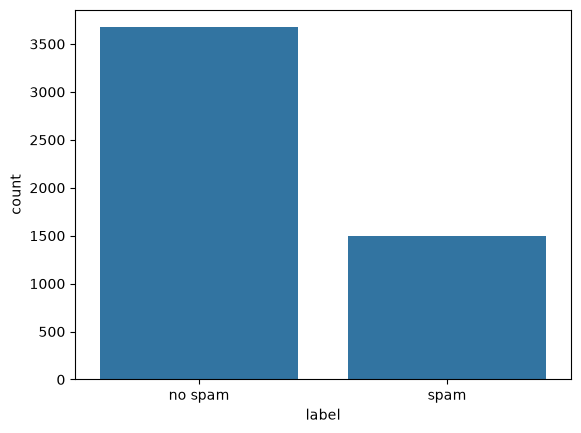

In [61]:
sn.countplot(data=df, x='label')

As we can see, there are much more legit messages than spam. This is quite normal, since most of the emails are usually legit in any normal inbox. This can make it a bit more difficult for the algorithms to identify properly the spam messages, but for now let's start building up the algorithm and check results step by step.

### Data preprocessing
We have a binary variable: spam or no spam, so we can transform that into numbers (1 or 0) to make it processable.

In [62]:
df['label'] = df['label'].apply(lambda x: 0 if x == 'no spam' else 1)
df.head()

,label,text
0,0,Subject: enron methanol ; meter # : 988291\nth...
1,0,"Subject: hpl nom for january 9 , 2001\n( see a..."
2,0,"Subject: neon retreat\nho ho ho , we ' re arou..."
3,1,"Subject: photoshop , windows , office . cheap ..."
4,0,Subject: re : indian springs\nthis deal is to ...


## Preprocessing and training
On this first stage, let's try to create a simple algorithm manipulating the data just to create **Bags of words** (explained below) and the train-test subsets.

We first split the dataset into the variables and the target.

In [63]:
X = df["text"]
y = df["label"]

Now, we get the train and test subsets

In [64]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = .2, random_state = 43)

### Text Vectorization with `CountVectorizer`

We use `CountVectorizer` from Scikit-learn to convert email text into numerical features that our machine learning model can understand.

- `CountVectorizer(max_features=1000)`: Creates a **Bag of Words** representation, counting how many times each word appears in the emails. It keeps only the 1,000 most frequent words in the vocabulary.
- `vect.fit_transform(X_train)`: Learns the vocabulary from the training data and transforms the emails into a document-term matrix, where each row represents an email and each column represents a word count.
- `vect.transform(X_test)`: Transforms the test emails using the same vocabulary learned from the training data, ensuring that both datasets have the same features without leaking information from the test set.
- `.toarray()`: Converts the resulting sparse matrices into dense NumPy arrays.

**Key idea:** `CountVectorizer` turns unstructured text into numerical data, allowing the model to learn patterns associated with spam emails.

**Note:** Converting sparse matrices to dense arrays can significantly increase memory usage, especially with large datasets. Keeping the data in sparse format can be more efficient.

In [65]:
from sklearn.feature_extraction.text import CountVectorizer

vect = CountVectorizer(max_features=1000)

bag_train = vect.fit_transform(X_train)
bag_test = vect.transform(X_test)

X_train = bag_train.toarray()
X_test = bag_test.toarray()

Now we train the model. We're going to use the RandomForestClassifier() in our first attempt and see how it performs seeing its metrics

In [66]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier()

model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [67]:
from sklearn.metrics import accuracy_score, confusion_matrix

yhat = model.predict(X_test)

print(f"ACCURACY: {accuracy_score(y_test, yhat)}")

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_test, yhat))

ACCURACY: 0.9632850241545894

CONFUSION MATRIX
[[704  26]
 [ 12 293]]


### Model Validation

We repeat the training and evaluation process 10 times using different random train-test splits, with 80% of the data for training and 20% for testing.

In each iteration:
- `train_test_split` splits the dataset into training and testing sets.
- `CountVectorizer` learns the vocabulary from the training emails and transforms both sets into numerical features.
- `RandomForestClassifier` is trained on the training data and evaluated on the test data.
- `accuracy_score` calculates the proportion of correctly classified emails.

Finally, we report the **minimum, average, and maximum accuracy** across the 10 iterations to understand how performance varies between splits.

**Important:** Accuracy alone is not sufficient for our spam detection task. We should also measure the false positive rate — the percentage of legitimate emails incorrectly classified as spam — to ensure it stays below our 1% target.

In [68]:
import numpy as np

metrics = []

for _ in range(10):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = .2)

    vect = CountVectorizer(max_features=1000)

    bag_train = vect.fit_transform(X_train)
    bag_test = vect.transform(X_test)

    X_train = bag_train.toarray()
    X_test = bag_test.toarray()
    
    model = RandomForestClassifier(random_state=43)

    model.fit(X_train, y_train)
    
    yhat = model.predict(X_test)
    
    acc = accuracy_score(y_test, yhat)
    metrics.append(acc)
    
print(f"MIN ACCURACY {min(metrics)}")
print(f"AVG ACCURACY {np.mean(metrics)}")
print(f"MAX ACCURACY {max(metrics)}")

MIN ACCURACY 0.9642512077294686
AVG ACCURACY 0.9747826086956521
MAX ACCURACY 0.9835748792270531


Although is not a bad result, we should try to improve the performance. We have to remember that our goal is to prevent than more of 1% of legit emails fall into the spam folder, so we'll need other metrics to check that out.

# Model improvement

- Implement a preprocessing pipeline that you believe could improve the model's performance.
- Evaluate the model using the approach you consider most appropriate given the problem's requirements.
- Validate the evaluation metrics.

### Extra

- Save the trained model and the preprocessing functions.
- Load the model and preprocessing functions. Apply the preprocessing to the data in `spam_no_labels.csv` and use the model to make predictions.

____________________________________

## Text Analysis and Email Cleaning

The first thing we notice when inspecting some email messages is that the text is not clean. In other words, each email may contain a significant amount of **noise**, such as stopwords, punctuation, inconsistent capitalization, URLs, numbers, and other special characters.

These elements may increase the complexity of the text representation without necessarily providing useful information for spam detection. Cleaning the text can help reduce the number of features the model needs to process, potentially improving computational efficiency and generalization.

We can also observe that the word `subject`, which indicates the beginning of an email's subject line, appears at the start of many messages. Since this is a structural marker rather than meaningful content, it may not contribute much to the classification task. We will remove it only when it appears at the beginning of the text, leaving any occurrences within the email body untouched.

Another potentially useful technique is **lemmatization**, which reduces words to their base or dictionary form. For example, *"running"* and *"runs"* can be reduced to *"running"* and *"run"*, respectively, depending on the lemmatization rules. This can help group related word forms and reduce the number of distinct features in the resulting vocabulary.

Our preprocessing pipeline will therefore include the following steps:

1. **Convert text to lowercase** to avoid treating uppercase and lowercase versions of the same word as different features.
2. **Remove special characters, numbers, and punctuation** to reduce irrelevant textual noise.
3. **Remove stopwords**, such as common words that may contribute little to classification.
4. **Apply lemmatization** to normalize word forms and potentially reduce vocabulary size.
5. **Remove the `subject` prefix** only when it appears at the beginning of an email.
6. **Replace URLs and email addresses with the tokens URL and EMAIL.** These patterns can be useful spam indicators, and preserving them allows the model to learn their predictive value without retaining the full addresses.
**Note:** The current cleaning step removes the uppercase letters in URL and EMAIL, leaving the lowercase tokens url and email. This is fine, as long as they remain consistent across the dataset.

By reducing unnecessary variation and noise in the text, we aim to build a more efficient model without removing information that could be useful for distinguishing spam from legitimate emails.

### Import libraries
First thigs first. Let's import the necessary libraries to build our model. We'll apply regex expresions, Natural Language Processing (NLP) and use some metrics to evaluate our model's performance.

In [69]:
import re
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import precision_score, recall_score, accuracy_score, f1_score

import seaborn as sns
import matplotlib.pyplot as plt

Reimport the dataset

In [70]:
df = pd.read_csv("Data/spam.csv")
df['label'] = df['label'].apply(lambda x: 0 if x == 'no spam' else 1)
df.head()

,label,text
0,0,Subject: enron methanol ; meter # : 988291\nth...
1,0,"Subject: hpl nom for january 9 , 2001\n( see a..."
2,0,"Subject: neon retreat\nho ho ho , we ' re arou..."
3,1,"Subject: photoshop , windows , office . cheap ..."
4,0,Subject: re : indian springs\nthis deal is to ...


Taking a quick look to the texts of the emails, we can see the word *Subject* at the beginning of each one, which is not going to be useful.

In [71]:
df['text'][0]

"Subject: enron methanol ; meter # : 988291\nthis is a follow up to the note i gave you on monday , 4 / 3 / 00 { preliminary\nflow data provided by daren } .\nplease override pop ' s daily volume { presently zero } to reflect daily\nactivity you can obtain from gas control .\nthis change is needed asap for economics purposes ."

Now, we apply everything using a function, and later we remove the word "subject"

In [107]:
# if needed, download stopwords: nltk.download('stopwords'), nltk.download('wordnet')
stop_words = set(stopwords.words('english'))  
lemmatizer = WordNetLemmatizer()

def preprocesar_texto(texto):
    # Convert text to lowercase
    texto = texto.lower()

    # Replace URLs and email addresses with special tokens
    texto = re.sub(r'https?://\S+|www\.\S+', ' URL ', texto)
    texto = re.sub(r'\b[\w.-]+@[\w.-]+\.\w+\b', ' EMAIL ', texto)

    # Remove special characters, numbers, and punctuation
    texto = re.sub(r'[^a-z ]', '', texto)

    # Remove stopwords
    texto = ' '.join([palabra for palabra in texto.split() if palabra not in stop_words])

    # Lemmatize words
    texto = ' '.join([lemmatizer.lemmatize(palabra) for palabra in texto.split()])

    # Remove "subject" only when it appears at the beginning
    texto = re.sub(r'^subject\s+', '', texto)
    
    return texto

In [ ]:
# Apply preprocessing to the whole column
df['text'] = df['text'].apply(preprocesar_texto)

# Replace "subject" only at the beginning of the email
# df['text'] = df['text'].apply(lambda x: re.sub(r'^subject ', '', x))

Let's take a look now:

In [74]:
df['text'][0]

'enron methanol meter follow note gave monday preliminaryflow data provided daren please override pop daily volume presently zero reflect dailyactivity obtain gas control change needed asap economics purpose'

### Train the model
Now that we have the dataset ready, we can train a model with it.

In [75]:
# Split into variables and target + train/test subsets
X = df['text']
y = df['label']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=43, stratify=y)

Here, we get the vectorized X train and test subsets.

In [76]:
def vectorizador(m_feat):
    vect = CountVectorizer(max_features=m_feat)
    X_train_vect = vect.fit_transform(X_train)
    X_test_vect = vect.transform(X_test)
    return X_train_vect, X_test_vect

The prediction function as a pipeline for the whole prediction process:

In [77]:
def predictor(X_train_vect, X_test_vect):    

    # Train model
    model = RandomForestClassifier(class_weight={0:2, 1:1}, random_state=43)
    model.fit(X_train_vect, y_train)

    # Predictions
    y_pred = model.predict(X_test_vect)

    return y_pred

In [78]:
X_train_vect, X_test_vect = vectorizador(m_feat=5000)

In [79]:
y_pred = predictor(X_train_vect, X_test_vect)

## Model Validation: Confusion Matrix and Performance Metrics

The goal is to ensure that **fewer than 1% of legitimate emails are incorrectly classified as spam**, while maintaining strong overall performance.

This means we must pay particular attention to the **False Positive Rate (FPR)** and ensure that it remains below 1%. We should also monitor **Accuracy, Precision, and Recall** to ensure that the model performs well across the different classification metrics.

To evaluate our model, we use a **confusion matrix** to visualize the number of correct and incorrect predictions for each class. This helps us identify legitimate emails incorrectly classified as spam, which is our main concern.

We also use `classification_report` to calculate Precision, Recall, F1-score, and Accuracy. By analyzing these metrics alongside the confusion matrix, we can assess the model's overall performance and determine whether it meets our requirements.

In [80]:
def plot_confusion_matrix(y_true, y_pred, labels=None, normalize=False, cmap="Blues"):
    """
    Plotea la matriz de confusión de forma visual con Seaborn.
    
    Parámetros:
    - y_true: array-like. Valores reales de la etiqueta.
    - y_pred: array-like. Valores predichos por el modelo.
    - labels: list. Lista de etiquetas para las clases (opcional).
    - normalize: bool. Si es True, muestra porcentajes en lugar de valores absolutos.
    - cmap: str. Mapa de colores para el gráfico (por defecto "Blues").
    """
    # Crear la matriz de confusión
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    
    # Normalizar la matriz si es necesario
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    # Crear un DataFrame para usar en Seaborn
    labels = labels if labels else [str(i) for i in range(cm.shape[0])]
    cm_df = pd.DataFrame(cm, index=labels, columns=labels)

    # Plotear con Seaborn
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm_df, annot=True, fmt=".2f" if normalize else "d", cmap=cmap, cbar=False)
    
    # Configuración del gráfico
    plt.title("Confusion Matrix", fontsize=16)
    plt.xlabel("Prediction", fontsize=14)
    plt.ylabel("Real value", fontsize=14)
    plt.xticks(ticks=np.arange(len(labels)) + 0.5, labels=labels, rotation=45)
    plt.yticks(ticks=np.arange(len(labels)) + 0.5, labels=labels, rotation=0)
    plt.tight_layout()
    plt.show()


In [81]:
print(classification_report(y_test, y_pred, target_names=["Legit", "Spam"]))

              precision    recall  f1-score   support

       Legit       0.99      0.99      0.99       735
        Spam       0.96      0.96      0.96       300

    accuracy                           0.98      1035
   macro avg       0.97      0.97      0.97      1035
weighted avg       0.98      0.98      0.98      1035



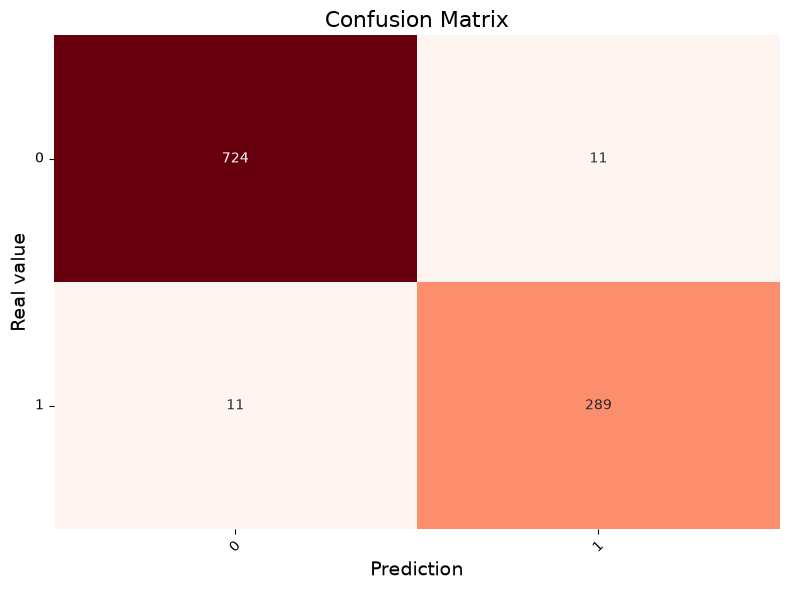

In [82]:
plot_confusion_matrix(y_test, y_pred, cmap='Reds')

In [83]:
cm = confusion_matrix(y_test, y_pred)

# specific metrics
tn, fp, fn, tp = cm.ravel()
fpr = fp / (fp + tn)  # False Positive Rate (FPR)

In [84]:
print(f"False Positive Rate (FPR): {fpr:.4f}")
print("Accuracy:"     , accuracy_score(y_test, y_pred))
print("Precision:"    , precision_score(y_test, y_pred, average = "macro"))
print("Sensitivity:" , recall_score(y_test, y_pred, average = "macro"))
print("F1-score:"     , f1_score(y_test, y_pred, average = "macro"))

False Positive Rate (FPR): 0.0150
Accuracy: 0.978743961352657
Precision: 0.9741836734693878
Sensitivity: 0.9741836734693878
F1-score: 0.9741836734693878


### Evaluation Metrics

The results show that our model achieves an **Accuracy of 97.87%**, with strong overall Precision, Recall, and F1-score.

However, the **False Positive Rate (FPR) is 1.5%**, which is almost hitting our target of less than 1%. This means that the model incorrectly classifies approximately 1.5% of legitimate emails as spam.

Although the model performs well overall, we can try to improve it a bit more. We must prioritize reducing false positives while maintaining high spam detection performance.

## Next improvements
To get the required 1% or less of legit messages classified as spam, we can play with different parameters:
- **Adjust the model's probability threshold.** By default, our model considers as non-legit those emails with more than a 50% of probabilities of being spam. We can try to adjust that threshold. For example, if we consider 70%, the model will consider spam only those emails the algorithm is sure at least in a 70%. We can actually try different thresholds to see how they perform.
- **Increase max_features in CountVectorizer.** Considering more word into the calculations might increase the computtional cost, but improve the validation results. We can try some values until the improvement is minimal.

In [85]:
for mf in [1000, 3000, 5000, 7000, 9000]:

    X_train_vect, X_test_vect = vectorizador(m_feat=mf)
    y_pred = predictor(X_train_vect, X_test_vect)
    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()
    fpr = fp / (fp + tn)

    print(f"False Positive Rate (FPR) with max_features={mf}: {fpr:.4f}")

False Positive Rate (FPR) with max_features=1000: 0.0150
False Positive Rate (FPR) with max_features=3000: 0.0177
False Positive Rate (FPR) with max_features=5000: 0.0150
False Positive Rate (FPR) with max_features=7000: 0.0231
False Positive Rate (FPR) with max_features=9000: 0.0163


There is no deifference between using max:fetarues 1000 or 5000. With other values, the FPR is a bit higher. For a better computational performance, we'll choose 1000.

In [86]:
X_train_vect, X_test_vect = vectorizador(m_feat=1000)
y_pred = predictor(X_train_vect, X_test_vect)

spam_idx = list(model.classes_).index(1) #get spam index
probs = model.predict_proba(X_test_vect)[:, spam_idx]

for threshold in [0.5, 0.6, 0.7, 0.8, 0.9]:
    y_pred = (probs >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    fpr = fp / (fp + tn)
    spam_recall = tp / (tp + fn)

    print(
        f"Threshold={threshold:.1f} | "
        f"FPR={fpr:.2%} | "
        f"Spam Recall={spam_recall:.2%}"
    )

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
fpr = fp / (fp + tn)

print(f"False Positive Rate (FPR) with max_features={mf}: {fpr:.4f}")

Threshold=0.5 | FPR=49.25% | Spam Recall=54.00%
Threshold=0.6 | FPR=38.37% | Spam Recall=46.00%
Threshold=0.7 | FPR=24.08% | Spam Recall=32.67%
Threshold=0.8 | FPR=13.61% | Spam Recall=15.67%
Threshold=0.9 | FPR=1.36% | Spam Recall=1.00%
False Positive Rate (FPR) with max_features=9000: 0.0136


In [87]:
from sklearn.pipeline import Pipeline

In [88]:
# Create pipeline
pipeline = Pipeline([
    ('vectorizer', CountVectorizer(max_features=1000)),
    ('classifier', RandomForestClassifier(class_weight={0: 2, 1: 1}, random_state=43, n_jobs=-1))
])

# Train model
pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('vectorizer', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"max_features max_features: int, default=NoneIf not None, build a vocabulary that only consider the top`max_features` ordered by term frequency across the corpus.Otherwise, all features are used.This parameter is ignored if vocabulary is not None.",1000
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None


In [89]:
# Get spam class index
spam_idx = list(pipeline.classes_).index(1)

# Get spam probabilities
probs = pipeline.predict_proba(X_test)[:, spam_idx]

# Test different thresholds
for threshold in [0.5, 0.6, 0.7, 0.8, 0.9]:

    y_pred = (probs >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    fpr = fp / (fp + tn)
    spam_recall = tp / (tp + fn)

    print(
        f"Threshold: {threshold:.2f} | "
        f"FPR: {fpr:.2%} | "
        f"Spam Recall: {spam_recall:.2%}"
    )

Threshold: 0.50 | FPR: 1.50% | Spam Recall: 95.67%
Threshold: 0.60 | FPR: 1.22% | Spam Recall: 91.00%
Threshold: 0.70 | FPR: 0.54% | Spam Recall: 74.33%
Threshold: 0.80 | FPR: 0.27% | Spam Recall: 60.00%
Threshold: 0.90 | FPR: 0.00% | Spam Recall: 38.67%


In [90]:
# Get spam class index
spam_idx = list(pipeline.classes_).index(1)

# Get spam probabilities
probs = pipeline.predict_proba(X_test)[:, spam_idx]

# Test different thresholds
for threshold in [0.6, 0.62, 0.64, 0.66, 0.68]:

    y_pred = (probs >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    fpr = fp / (fp + tn)
    spam_recall = tp / (tp + fn)

    print(
        f"Threshold: {threshold:.2f} | "
        f"FPR: {fpr:.2%} | "
        f"Spam Recall: {spam_recall:.2%}"
    )

Threshold: 0.60 | FPR: 1.22% | Spam Recall: 91.00%
Threshold: 0.62 | FPR: 1.09% | Spam Recall: 88.67%
Threshold: 0.64 | FPR: 0.95% | Spam Recall: 84.33%
Threshold: 0.66 | FPR: 0.68% | Spam Recall: 81.67%
Threshold: 0.68 | FPR: 0.54% | Spam Recall: 78.00%


________________________
# Independent validation and pipeline configuration
Now that we have a good parameter combination, we can perform the whole process carrying out an independent validation, spliting the dataset into train, teat and validation subsets. We'll also build the pipeline to make the process straight forward.

Firste, import libraries, dataset, and data preparation.

In [108]:
import re
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

import seaborn as sn

from sklearn.preprocessing import FunctionTransformer
from sklearn.model_selection import train_test_split

from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import precision_score, recall_score, accuracy_score, f1_score

In [111]:
df = pd.read_csv("Data/spam.csv")
df['label'] = df['label'].apply(lambda x: 0 if x == 'no spam' else 1)

In [112]:
def preprocess_batch(texts):
    return [preprocesar_texto(text) for text in texts]

Once ready, we train and test the model. For an independent validation:
- **Use the 80% of data for train/test purposes.** This will be called X_dev and y_dev. We save 20% of the data for the final independent validation.
- **The saved 80% is split again in train/test subsets.** 

In [113]:
X = df['text']
y = df['label']

# First, reserve the final test set for validation
X_dev, X_val, y_dev, y_val = train_test_split(
    X, y,
    test_size=0.20,
    random_state=43,
    stratify=y
)

# Split the development data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X_dev, y_dev,
    test_size=0.2,
    random_state=43,
    stratify=y_dev
)

print("Training:", len(X_train))
print("Test:", len(X_test))
print("Validation:", len(X_val))

Training: 3308
Test: 828
Validation: 1035


Build the pipeline.

In [114]:
pipeline = Pipeline([
    ('preprocessor', FunctionTransformer(preprocess_batch, validate=False)),
    ('vectorizer', CountVectorizer(max_features=1000)),
    ('classifier', RandomForestClassifier(
        class_weight={0: 2, 1: 1},
        random_state=43,
        n_jobs=-1
    ))
])

# Train the model
pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('vectorizer', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function pre...0026EFF7CEFC0>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True


Apply the pipeline and get the best threshold posible.

In [115]:
spam_idx = list(pipeline.classes_).index(1)
test_probs = pipeline.predict_proba(X_test)[:, spam_idx]

best_threshold = None
best_recall = -1
best_fpr = None

for threshold in np.arange(0.01, 1.00, 0.01):

    test_pred = (test_probs >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, test_pred, labels=[0, 1]
    ).ravel()

    fpr = fp / (fp + tn)
    spam_recall = tp / (tp + fn)

    if fpr < 0.01 and spam_recall > best_recall:
        best_threshold = threshold
        best_recall = spam_recall
        best_fpr = fpr

if best_threshold is not None:
    print(f"Best threshold: {best_threshold:.2f}")
    print(f"Validation FPR: {best_fpr:.2%}")
    print(f"Validation Spam Recall: {best_recall:.2%}")
else:
    print("No threshold achieved an FPR below 1%.")

Best threshold: 0.65
Validation FPR: 0.85%
Validation Spam Recall: 77.92%


Now we can use the best threshold to carry out the independent validation with the validation subset, X_val and y_val.

In [116]:
val_probs = pipeline.predict_proba(X_val)[:, spam_idx]

y_val_pred = (val_probs >= best_threshold).astype(int)

# Confusion matrix
cm = confusion_matrix(y_val, y_val_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

# Main metrics
fpr = fp / (fp + tn)
spam_recall = tp / (tp + fn)

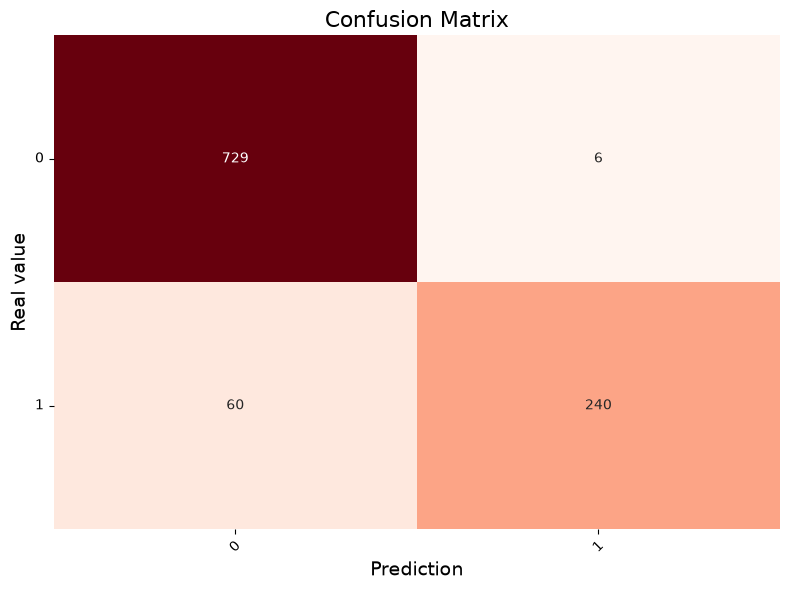


CLASSIFICATION REPORT
              precision    recall  f1-score   support

       Legit       0.92      0.99      0.96       735
        Spam       0.98      0.80      0.88       300

    accuracy                           0.94      1035
   macro avg       0.95      0.90      0.92      1035
weighted avg       0.94      0.94      0.93      1035

Threshold: 0.65
FPR: 0.82%
Spam Recall: 80.00%
Accuracy: 93.62%


In [117]:
plot_confusion_matrix(y_val, y_val_pred, cmap='Reds')

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_val,
    y_val_pred,
    target_names=["Legit", "Spam"]
))

print(f"Threshold: {best_threshold:.2f}")
print(f"FPR: {fpr:.2%}")
print(f"Spam Recall: {spam_recall:.2%}")
print(f"Accuracy: {accuracy_score(y_val, y_val_pred):.2%}")

We can now store the model.

In [118]:
import pickle

model_data = {
    'pipeline': pipeline,
    'threshold': best_threshold
}

with open('spam_detection_model.pkl', 'wb') as file:
    pickle.dump(model_data, file)

print("Model saved successfully.")

Model saved successfully.
